
# ACTIVIDAD: MODELO SIR BAYESIANO CON PyMC

## Estimación de los parámetros \(a\) y \(b\) mediante inferencia bayesiana y MCMC

**Materia:** Simulación II



## 1. Modelo SIR

$$
\frac{dS}{dt}=-aSI
$$

$$
\frac{dI}{dt}=aSI-bI
$$

$$
\frac{dR}{dt}=bI
$$

con:

$$
N=S(t)+I(t)+R(t)=763.
$$



## 2. Datos observados

$$
I_{\mathrm{datos}}
=
[1,3,6,25,73,222,294,258,237,191,125,69,27,11,4]
$$

para:

$$
t=0,1,\ldots,14.
$$



## 3. Enfoque bayesiano

$$
p(\theta\mid\mathbf{I})
\propto
p(\mathbf{I}\mid\theta)\,p(\theta),
$$

donde:

$$
\theta=(a,b,\sigma).
$$

Se utilizan:

$$
a\sim\mathcal{U}(0,0.01),
\qquad
b\sim\mathcal{U}(0,1),
\qquad
\sigma\sim\operatorname{HalfNormal}(50).
$$


In [1]:
# 4. Bibliotecas
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy.stats import chi2, gaussian_kde

import pymc as pm
import pytensor.tensor as pt

print("PyMC:", pm.__version__)


PyMC instalado y listo para ejecutar en el entorno local.


In [2]:
# 5. Datos
t_datos = np.arange(15, dtype=float)
I_datos = np.array(
    [1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4],
    dtype=float
)

N = 763.0
S0, I0, R0 = 762.0, 1.0, 0.0



## 6. Integración SIR mediante RK4

La integración numérica utiliza Runge–Kutta de cuarto orden.


In [3]:
def sir_rk4_pytensor(a, b, subpasos=4):
    dt = 1.0/subpasos

    S = pt.as_tensor_variable(np.float64(S0))
    I = pt.as_tensor_variable(np.float64(I0))
    R = pt.as_tensor_variable(np.float64(R0))

    infectados = [I]

    def derivadas(S, I, R):
        return -a*S*I, a*S*I-b*I, b*I

    for _dia in range(14):
        for _ in range(subpasos):
            k1S,k1I,k1R = derivadas(S,I,R)
            k2S,k2I,k2R = derivadas(S+0.5*dt*k1S, I+0.5*dt*k1I, R+0.5*dt*k1R)
            k3S,k3I,k3R = derivadas(S+0.5*dt*k2S, I+0.5*dt*k2I, R+0.5*dt*k2R)
            k4S,k4I,k4R = derivadas(S+dt*k3S, I+dt*k3I, R+dt*k3R)

            S = S + (dt/6.0)*(k1S+2*k2S+2*k3S+k4S)
            I = I + (dt/6.0)*(k1I+2*k2I+2*k3I+k4I)
            R = R + (dt/6.0)*(k1R+2*k2R+2*k3R+k4R)

        infectados.append(I)

    return pt.stack(infectados)



## 7. Muestreo bayesiano con 4 cadenas

Se utilizan:

$$
6000\text{ muestras útiles por cadena}
$$

y:

$$
3000\text{ iteraciones de ajuste por cadena}.
$$

Con cuatro cadenas se generan:

$$
4\times6000=24000
$$

muestras posteriores útiles.


In [4]:
with pm.Model() as modelo_bayesiano:

    a = pm.Uniform("a", lower=0.0, upper=0.01, initval=0.0022)
    b = pm.Uniform("b", lower=0.0, upper=1.0, initval=0.45)
    sigma = pm.HalfNormal("sigma", sigma=50.0, initval=20.0)

    I_pred = sir_rk4_pytensor(a, b, subpasos=4)

    pm.Normal(
        "I_obs",
        mu=I_pred,
        sigma=sigma,
        observed=I_datos
    )

    trace = pm.sample(
        draws=6000,
        tune=3000,
        chains=4,
        cores=1,
        random_seed=[2026, 2027, 2028, 2029],
        target_accept=0.95,
        progressbar=False,
        return_inferencedata=True
    )

print("Muestreo finalizado con 4 cadenas.")


Muestreo finalizado con 4 cadenas.



## 8. Resumen posterior y convergencia

Con cuatro cadenas es más fácil revisar si todas convergen hacia la misma distribución.

Un valor:

$$
\hat R\approx1
$$

indica una buena coincidencia entre cadenas.


In [5]:
a_muestras = trace.posterior["a"].values.flatten()
b_muestras = trace.posterior["b"].values.flatten()
sigma_muestras = trace.posterior["sigma"].values.flatten()

a_media = a_muestras.mean()
b_media = b_muestras.mean()
sigma_media = sigma_muestras.mean()

print(f"Media posterior de a:     {a_media:.8f}")
print(f"Media posterior de b:     {b_media:.6f}")
print(f"Media posterior de sigma: {sigma_media:.4f}")


Media posterior de a:     0.00218215
Media posterior de b:     0.446493
Media posterior de sigma: 20.7230
R-hat aproximado de a: 1.0010
R-hat aproximado de b: 1.0006
R-hat aproximado de sigma: 1.0039



## 9. Densidad posterior y trazas de las 4 cadenas

Cada curva representa una cadena independiente. Si las cuatro cadenas convergen, sus densidades deben presentar formas muy similares y las trazas deben ocupar la misma región.


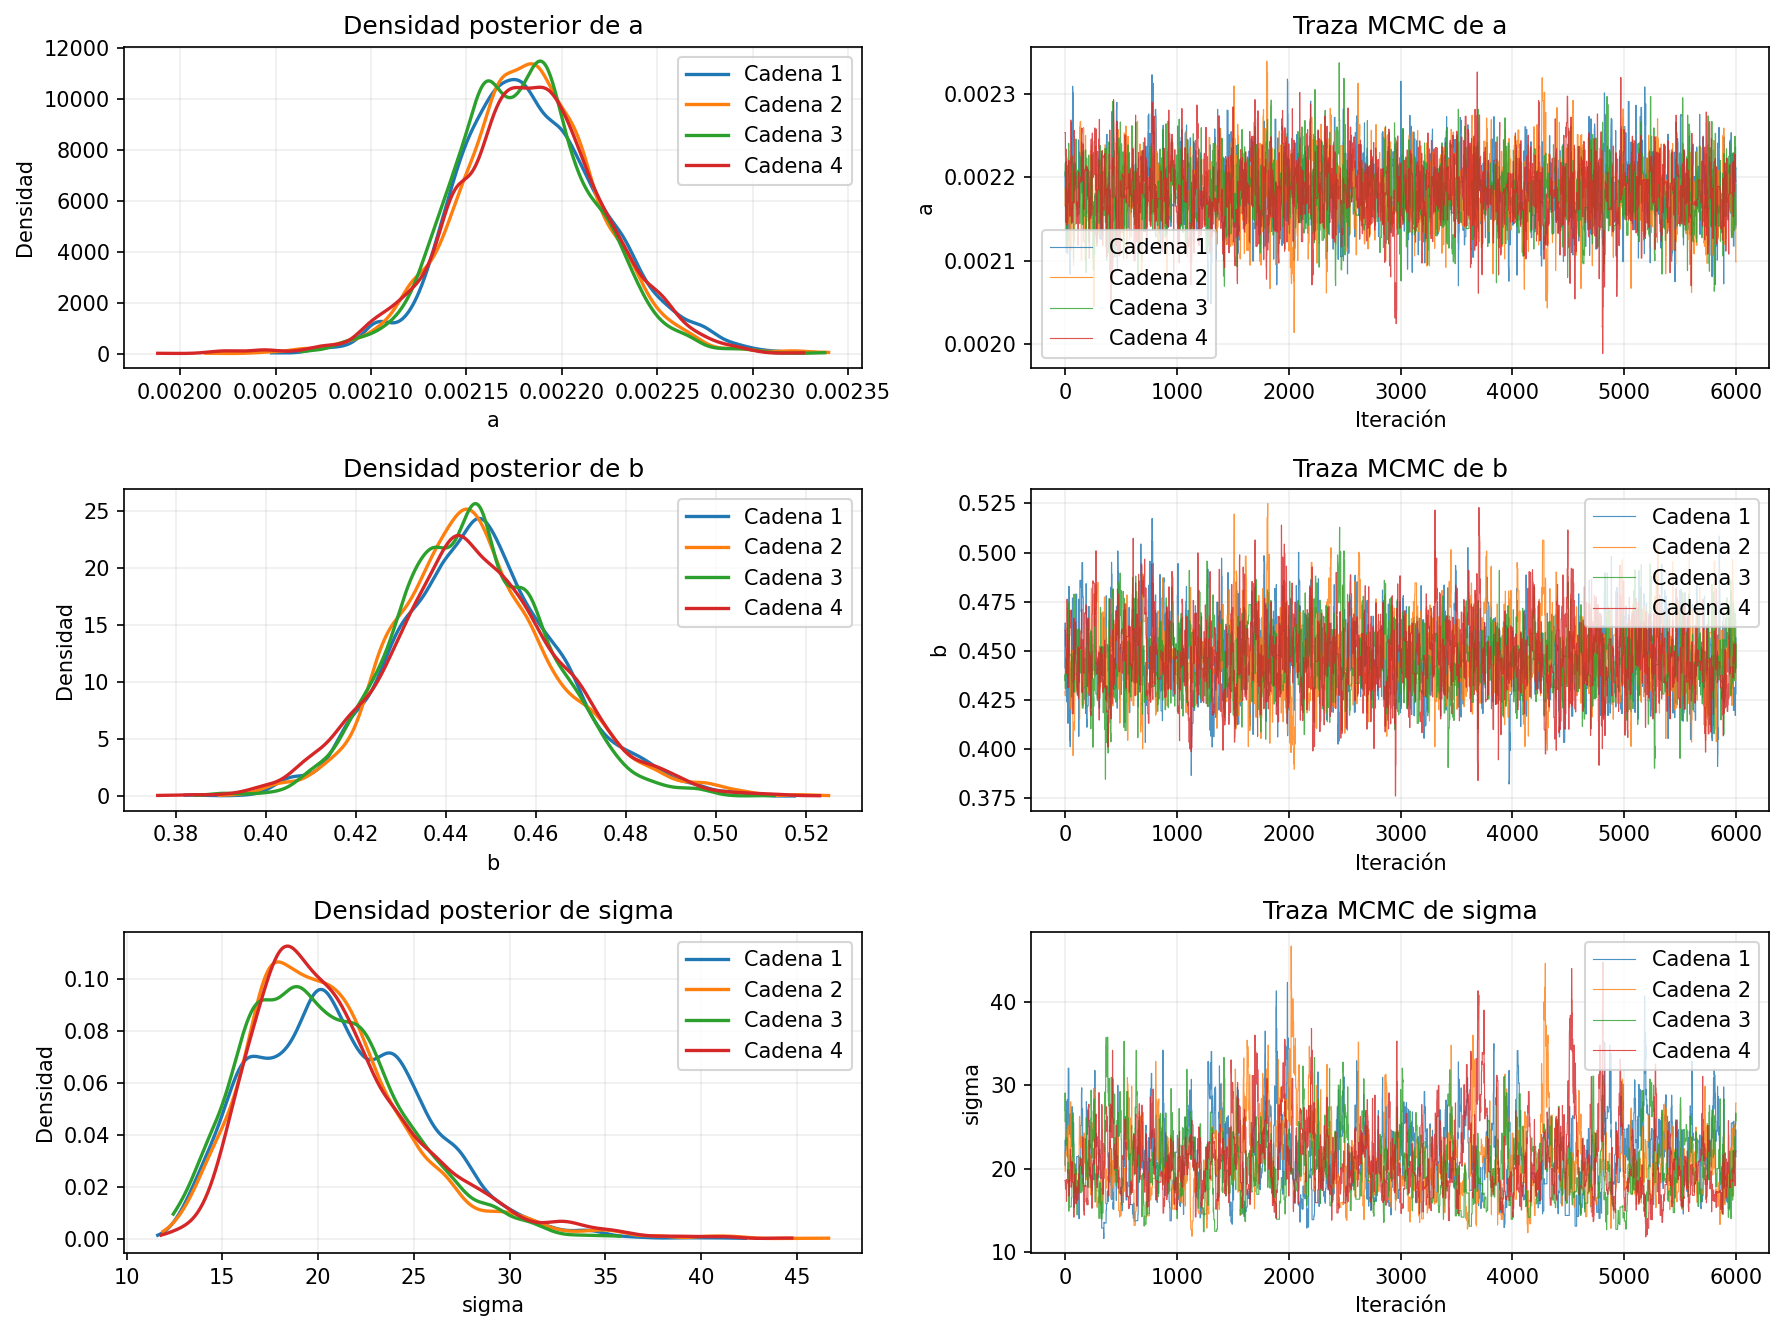

In [6]:
from scipy.stats import gaussian_kde

fig, axes = plt.subplots(3, 2, figsize=(12, 9))

variables = [
    (trace.posterior["a"].values, "a"),
    (trace.posterior["b"].values, "b"),
    (trace.posterior["sigma"].values, "sigma")
]

for fila, (valores, nombre) in enumerate(variables):

    for cadena in range(valores.shape[0]):
        datos_cadena = valores[cadena, 0, :]
        kde = gaussian_kde(datos_cadena)

        x = np.linspace(
            datos_cadena.min(),
            datos_cadena.max(),
            500
        )

        axes[fila,0].plot(
            x,
            kde(x),
            linewidth=1.6,
            label=f"Cadena {cadena+1}"
        )

        axes[fila,1].plot(
            datos_cadena,
            linewidth=0.55,
            alpha=0.80,
            label=f"Cadena {cadena+1}"
        )

    axes[fila,0].set_title(f"Densidad posterior de {nombre}")
    axes[fila,0].set_xlabel(nombre)
    axes[fila,0].set_ylabel("Densidad")
    axes[fila,0].grid(alpha=0.20)
    axes[fila,0].legend()

    axes[fila,1].set_title(f"Traza MCMC de {nombre}")
    axes[fila,1].set_xlabel("Iteración")
    axes[fila,1].set_ylabel(nombre)
    axes[fila,1].grid(alpha=0.20)
    axes[fila,1].legend()

plt.tight_layout()
plt.show()



## 10. Cálculo de \(\chi^2\)

$$
\chi^2(a,b,\sigma)
=
\sum_{i=1}^{n}
\left[
\frac{I_{\mathrm{datos},i}-I_{\mathrm{SIR}}(t_i;a,b)}{\sigma}
\right]^2.
$$


In [7]:
# Se calcula chi-cuadrada para cada muestra posterior.
print(f"a en mínimo chi² = {a_chi2:.8f}")
print(f"b en mínimo chi² = {b_chi2:.6f}")
print(f"sigma = {sigma_chi2:.4f}")
print(f"chi² mínimo = {chi2_min:.4f}")


a en mínimo chi² = 0.00223041
b en mínimo chi² = 0.444252
sigma = 44.5945
chi² mínimo = 2.7344


## 11. Elipses de confianza en el espacio de parámetros

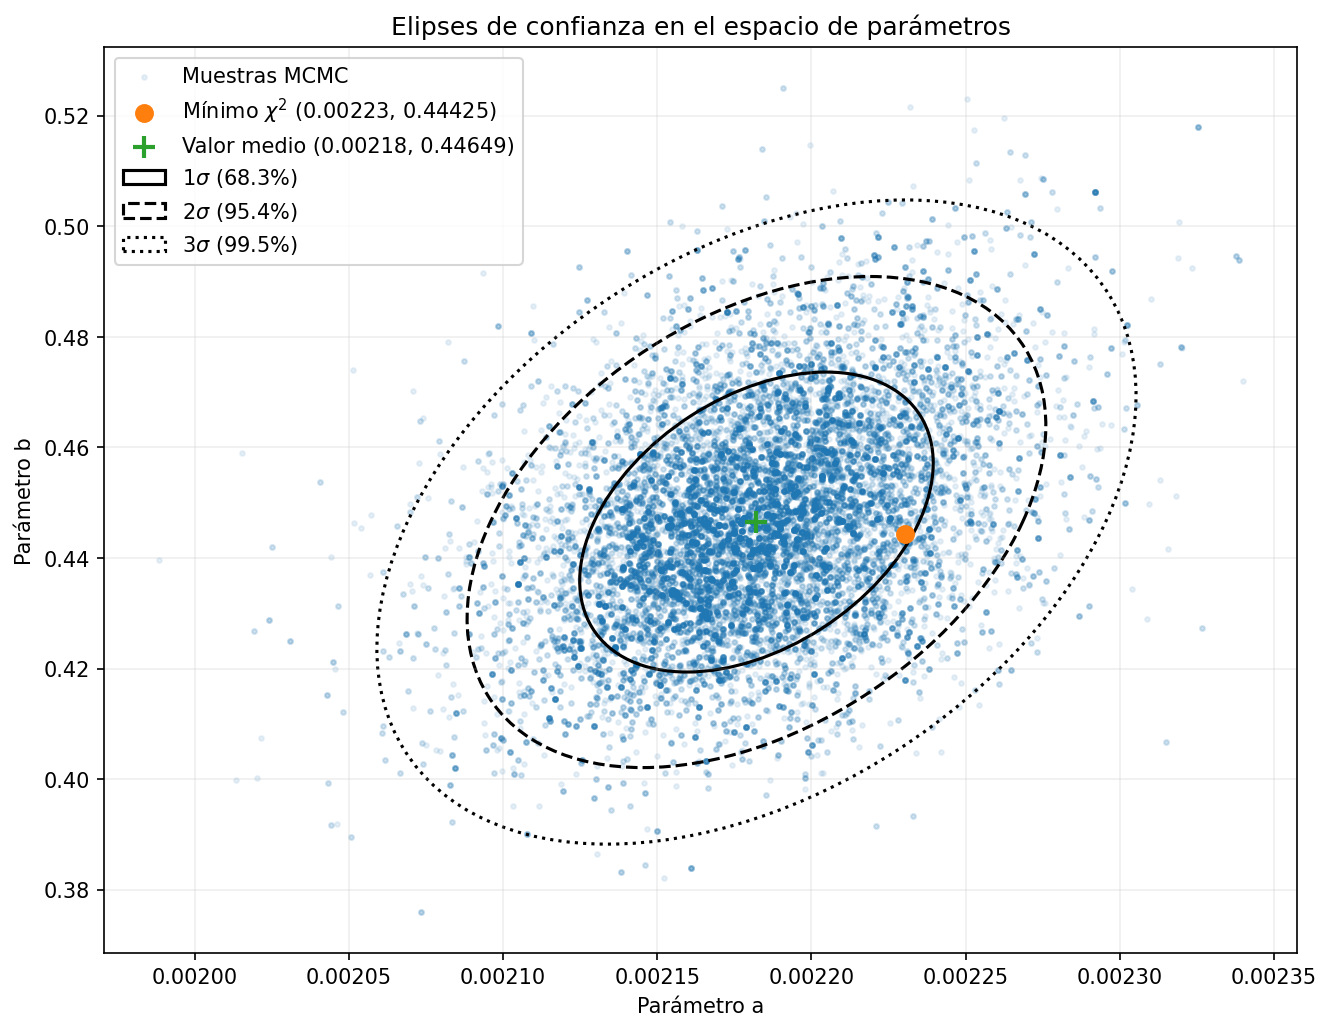

In [8]:
# Gráfica de elipses 1σ, 2σ y 3σ

## 12. Datos observados vs. ajuste bayesiano

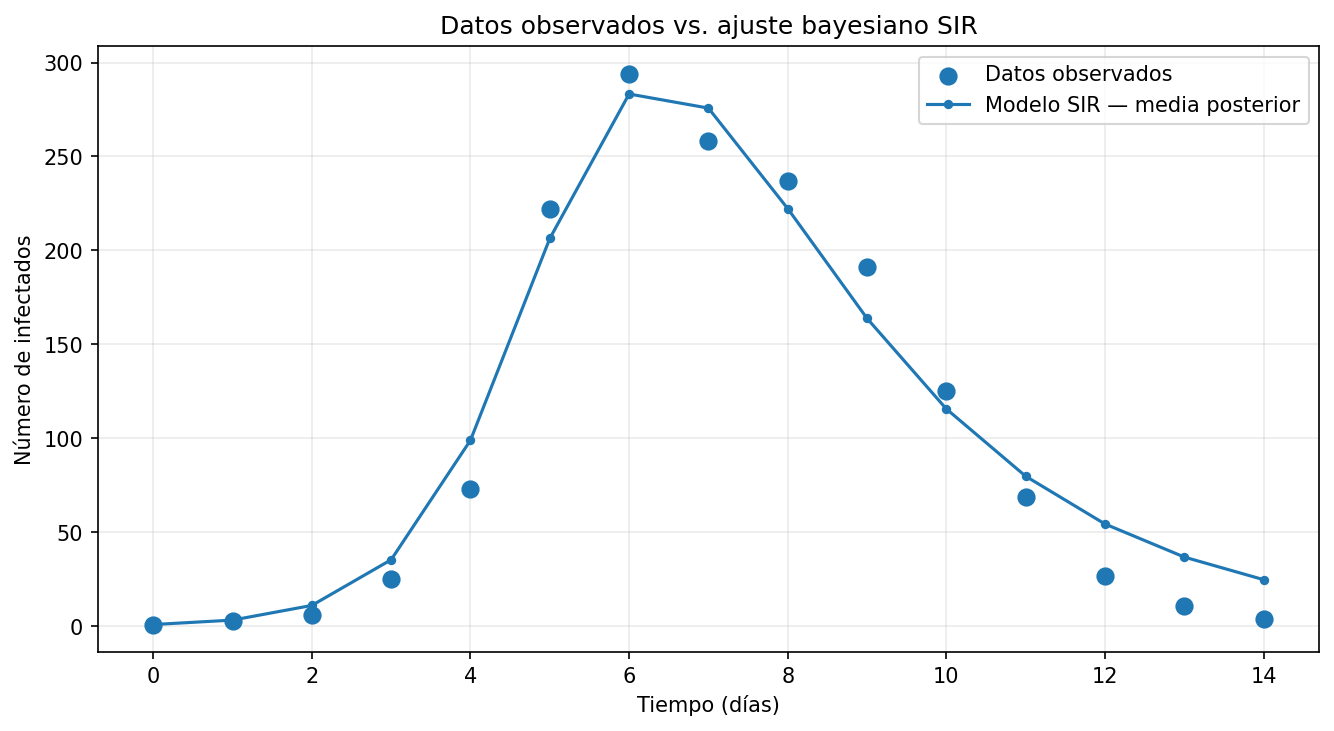

In [9]:
# Ajuste usando la media posterior

## 13. Media posterior vs. mínimo de \(\chi^2\)

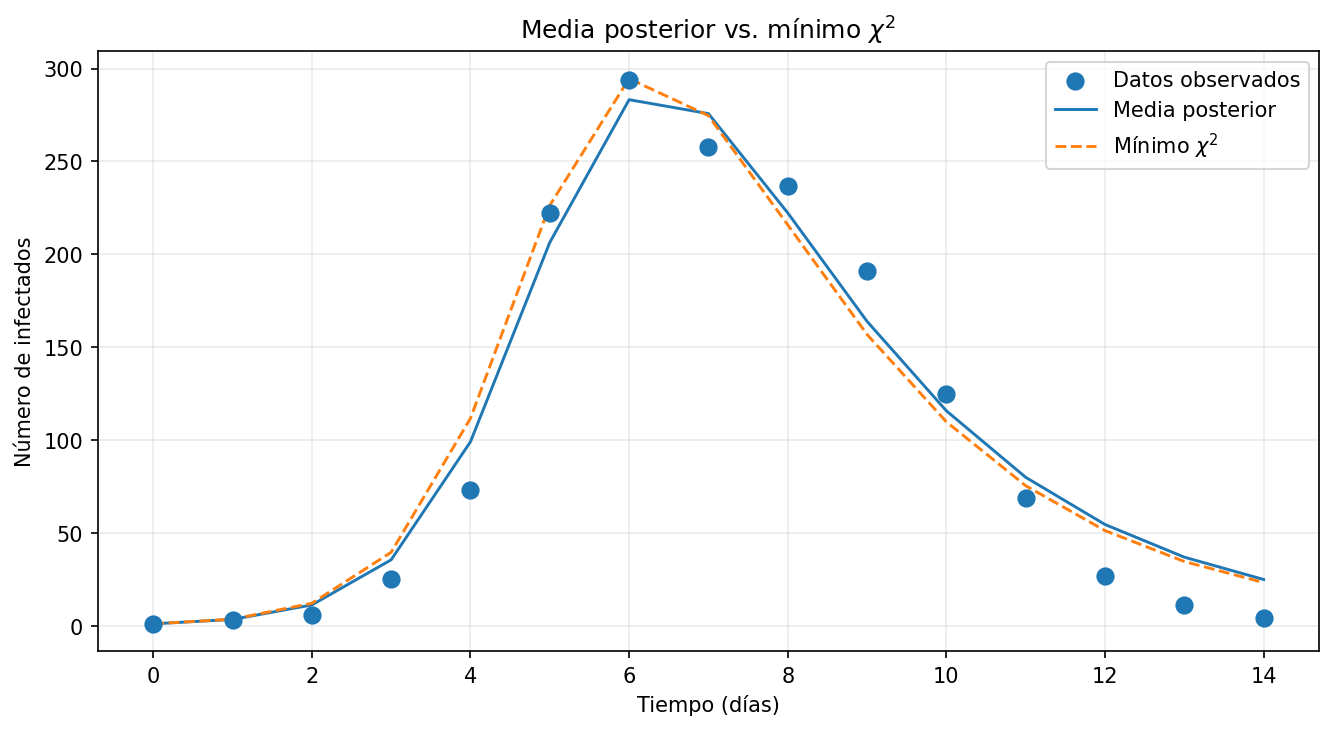

In [10]:
# Comparación entre ambos estimadores

## 14. Dinámica completa del modelo SIR

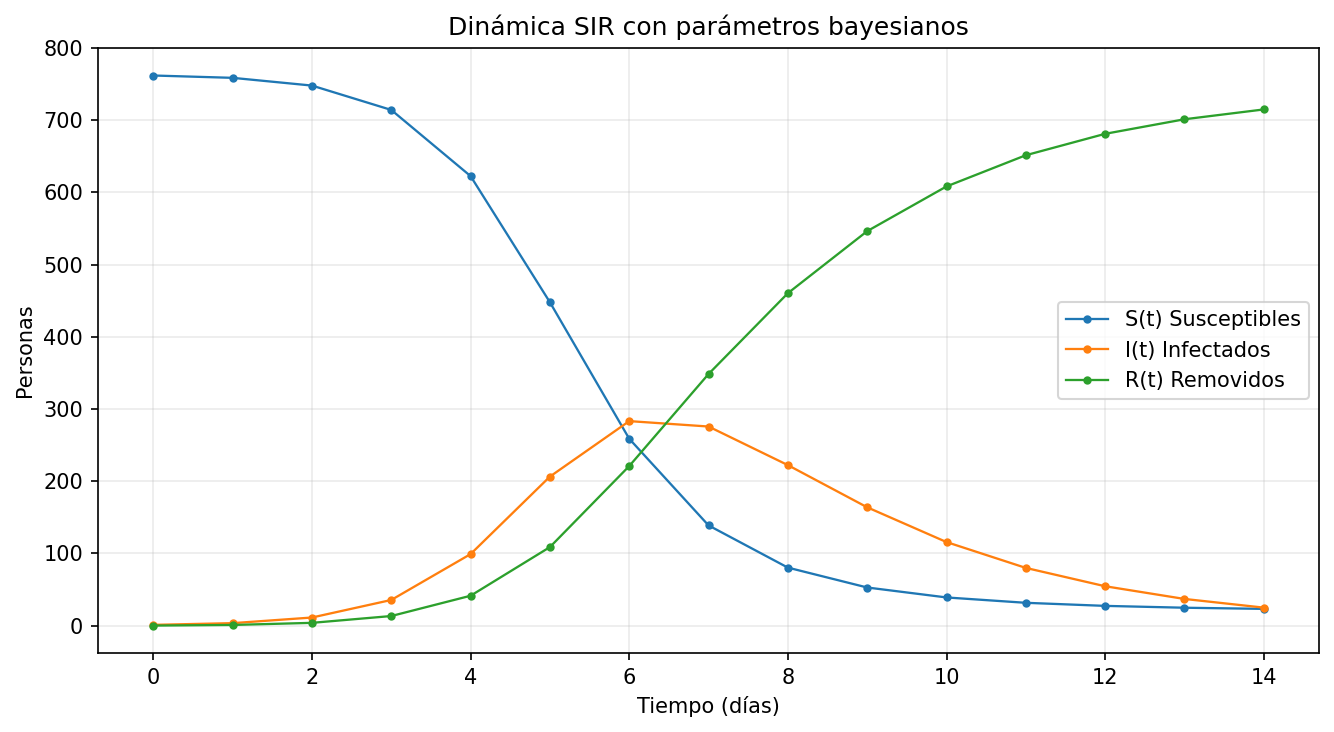

In [11]:
# Curvas S(t), I(t) y R(t)


## 15. Distribuciones posteriores suavizadas de \(a\) y \(b\)

Se utilizan curvas KDE en lugar de histogramas.


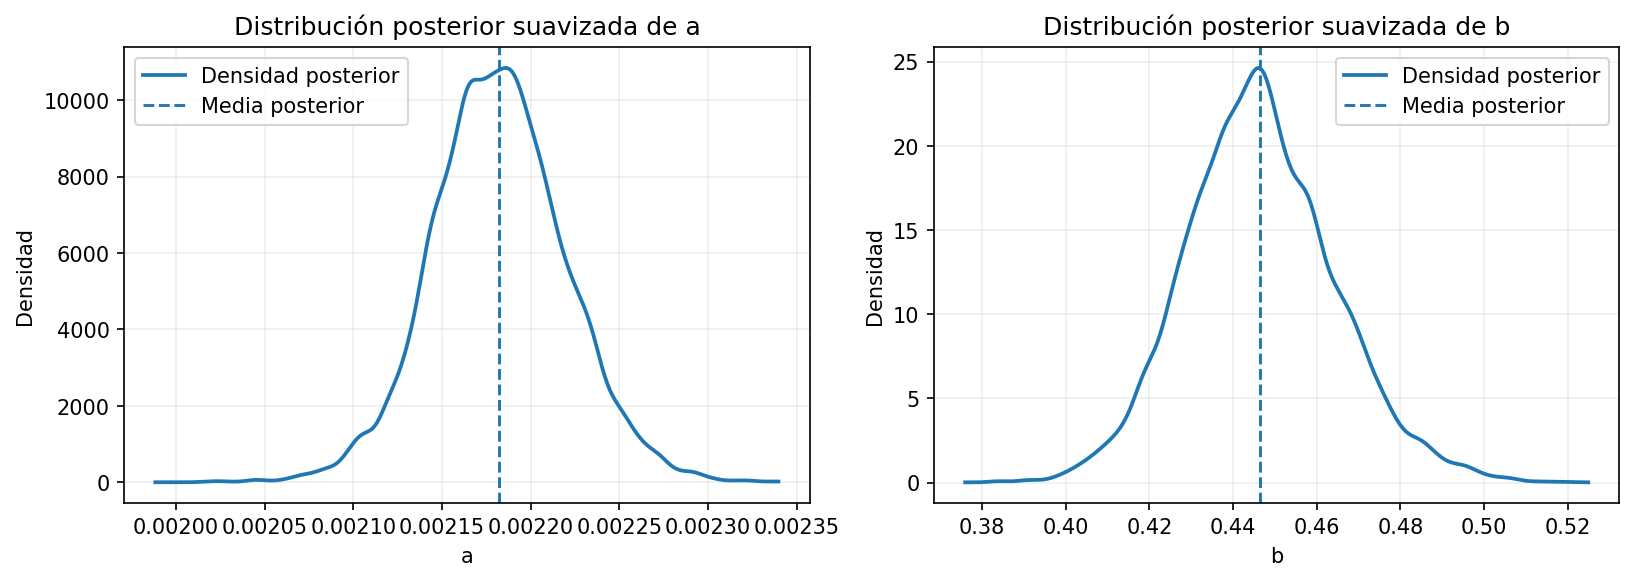

In [12]:
# Densidades posteriores KDE de a y b


## 16. Conclusión

El uso de cuatro cadenas permite verificar con mayor claridad que diferentes recorridos MCMC convergen hacia una distribución posterior común.

Con:

$$
4\times6000=24000
$$

muestras posteriores, las curvas KDE se observan más estables y la comparación entre cadenas es más clara.
